# Statics Homework 2 in SymPy: One Vector Sum, Six Subjects

Homework 2 (Hibbeler, *Statics*: 1-12, 1-18, 1-19, 2-8, 2-10, 2-46,
2-101) is, underneath, three operations:

1. **convert** a quantity between unit systems,
2. **resolve** a vector onto a set of axes (an inner product),
3. **add** vectors and demand that some components vanish.

This notebook does all seven problems exactly in SymPy, then shows the
same three operations reappearing in electricity & magnetism, recursion,
photonics, digital logic and statistics.

| Part | Subject | What carries over from statics |
|---|---|---|
| 1 | Units (Ch. 1) | exact rational conversion factors |
| 2 | Force vectors (Ch. 2) | resolve, add, solve |
| 3 | Electricity & magnetism | superposition of fields is a force resultant |
| 4 | Recursion | load path down a column, resistor ladder |
| 5 | Photonics 101 | a polarizer resolves **E** exactly like 2-8 resolves **F** |
| 6 | Digital logic | the ripple carry is the column recursion in Boolean form |
| 7 | Statistics | how uncertain is the answer to 2-46? |
| 8 | Worked steps | formula, numbers substituted, result — ready to copy by hand |
| 9 | Forces as exponentials | $Fe^{i\theta}$; many exponentials give interference |
| 10 | C and MATLAB | the same answers from two other languages |
| 11 | Reading map and time budget | which chapters, and how long it should take |
| 12 | Smart contracts (Ethereum) | exact integer units, a state machine, a hash recursion |

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from sympy import Rational, Matrix, sqrt, sin, cos, atan2, pi

deg = pi / 180                      # exact degrees -> radians
N3 = lambda e: sp.N(e, 3)           # three significant figures, like the textbook
sig3 = lambda e: float(f"{float(e):.3g}")   # same rounding as a plain float, for asserts
print("sympy", sp.__version__)

sympy 1.14.0


# Part 1 — Units (Chapter 1)

Two conversion factors are *exact by definition*: 1 ft = 0.3048 m and
1 lb = 4.448 221 615 260 5 N. The slug is not independent — it is the
mass that 1 lb accelerates at 1 ft/s², so
$1\ \text{slug} = 1\ \text{lb·s}^2/\text{ft}$. Keeping the factors as
rationals means SymPy carries no rounding until the last step.

In [2]:
ft   = Rational(3048, 10000)                 # m, exact
lb   = Rational(44482216152605, 10**13)      # N, exact
slug = lb / ft                               # kg  (lb s^2 / ft)
g    = Rational(981, 100)                    # m/s^2, textbook value

print("1 slug =", sp.N(slug, 6), "kg")

# 1-12: water, 1.94 slug/ft^3 -> SI
rho_water = Rational(194, 100) * slug / ft**3
print("1-12  rho =", sp.N(rho_water, 6), "kg/m^3  ->", N3(rho_water / 1000), "Mg/m^3")

# 1-18: (204 mm)(0.00457 kg)/(34.6 N)
val = Rational(204, 1000) * Rational(457, 100000) / Rational(346, 10)
print("1-18  value =", sp.N(val, 6), "m kg/N  ->", N3(val * 10**6), "um kg/N")

# 1-19: brass, specific weight 520 lb/ft^3 -> density
gamma = 520 * lb / ft**3                     # N/m^3
rho_brass = gamma / g
print("1-19  rho =", sp.N(rho_brass, 6), "kg/m^3  ->", N3(rho_brass / 1000), "Mg/m^3")

assert sig3(rho_water / 1000) == 1.0
assert sig3(val * 10**6) == 26.9
assert sig3(rho_brass / 1000) == 8.33

1 slug = 14.5939 kg
1-12  rho = 999.835 kg/m^3  -> 1.00 Mg/m^3
1-18  value = 2.69445e-5 m kg/N  -> 26.9 um kg/N
1-19  rho = 8326.76 kg/m^3  -> 8.33 Mg/m^3


**Dimension check on 1-18.** Since $1\ \text{N} = 1\ \text{kg·m/s}^2$,
the unit m·kg/N collapses to s². The answer $26.9\ \mu\text{m·kg/N}$ is
the form the textbook asks for, but it is numerically the same as
$26.9\times10^{-6}\ \text{s}^2$.

# Part 2 — Force vectors (Chapter 2)

## 2-8: resolving on axes that are *not* perpendicular

The $u$ and $v$ axes are 75° apart, so "the component along $u$" is not
simply $\mathbf F\cdot\hat u$. Write $\mathbf F_2 = a\,\hat u + b\,\hat v$
and dot both sides with $\hat u$ and $\hat v$:

$$\begin{pmatrix}\hat u\cdot\hat u & \hat u\cdot\hat v\\ \hat v\cdot\hat u & \hat v\cdot\hat v\end{pmatrix}
\begin{pmatrix}a\\ b\end{pmatrix}=\begin{pmatrix}\mathbf F_2\cdot\hat u\\ \mathbf F_2\cdot\hat v\end{pmatrix}$$

The matrix of inner products is the **Gram matrix**. For perpendicular
axes it is the identity and the components are plain dot products; here
it is not, which is exactly why the parallelogram law is needed.

Geometry: put $\hat u$ at 0°, then $\hat v$ is at +75° and $\mathbf F_2$
(30° on the far side of $u$) is at −30°.

In [3]:
unit = lambda a: Matrix([cos(a * deg), sin(a * deg)])

u, v = unit(0), unit(75)
F2 = 6 * unit(-30)                                   # kN

G   = Matrix([[u.dot(u), u.dot(v)], [v.dot(u), v.dot(v)]])   # Gram matrix
rhs = Matrix([F2.dot(u), F2.dot(v)])
a, b = [sp.simplify(c) for c in G.solve(rhs)]

print("Gram matrix:"); sp.pprint(G.applyfunc(sp.simplify))
print("\n2-8  F2u =", a, "=", N3(a), "kN")
print("2-8  F2v =", b, "=", N3(b), "kN   (negative: directed along -v)")

# law-of-sines check: triangle angles 30, 75, 75 degrees
b_sines = 6 * sin(30 * deg) / sin(75 * deg)
assert sp.simplify(a - 6) == 0
assert sp.simplify(b + b_sines) == 0

Gram matrix:
⎡             √2   √6⎤
⎢    1      - ── + ──⎥
⎢             4    4 ⎥
⎢                    ⎥
⎢  √2   √6           ⎥
⎢- ── + ──      1    ⎥
⎣  4    4            ⎦

2-8  F2u = 6 = 6.00 kN
2-8  F2v = -3*sqrt(6) + 3*sqrt(2) = -3.11 kN   (negative: directed along -v)


## 2-10 and 2-46: Cartesian components

On perpendicular axes the Gram matrix is the identity, so components
just add.

In [4]:
# 2-10: F1 = 400 N at 30 deg below +x, F3 = 250 N at 30 deg left of +y (120 deg from +x)
F1 = 400 * unit(-30)
F3 = 250 * unit(120)
FR = (F1 + F3).applyfunc(sp.simplify)
FR_mag = sp.simplify(FR.norm())
theta  = atan2(FR[1], FR[0])
print("2-10  FR =", list(FR), "N")
print("2-10  |FR| =", FR_mag, "=", N3(FR_mag), "N")
print("2-10  theta =", N3(theta / deg), "deg counterclockwise from +x")

# law-of-cosines check: interior angle of the force triangle is 30 deg
assert sp.simplify(FR_mag**2 - (400**2 + 250**2 - 2 * 400 * 250 * cos(30 * deg))) == 0

# 2-46: FA = 700 N at 30 deg from +y; resultant must be 1500 N along +y
FA = 700 * unit(60)
FB = Matrix([0, 1500]) - FA                 # whatever is missing is FB
FB_mag   = sp.simplify(FB.norm())
theta_B  = sp.atan(FB[1] / -FB[0])          # measured up from the -x axis
print("\n2-46  FB =", list(FB), "N")
print("2-46  |FB| =", N3(FB_mag), "N,  theta =", N3(theta_B / deg), "deg")

assert sig3(FR_mag) == 222.0 and sig3(theta / deg) == 4.26
assert sig3(FB_mag) == 960.0 and sig3(theta_B / deg) == 68.6

2-10  FR =

 [-125 + 200*sqrt(3), -200 + 125*sqrt(3)] N
2-10  |FR| = 50*sqrt(89 - 40*sqrt(3)) = 222. N
2-10  theta = 4.26 deg counterclockwise from +x

2-46  FB = [-350, 1500 - 350*sqrt(3)] N
2-46  |FB| = 960. N,  theta = 68.6 deg


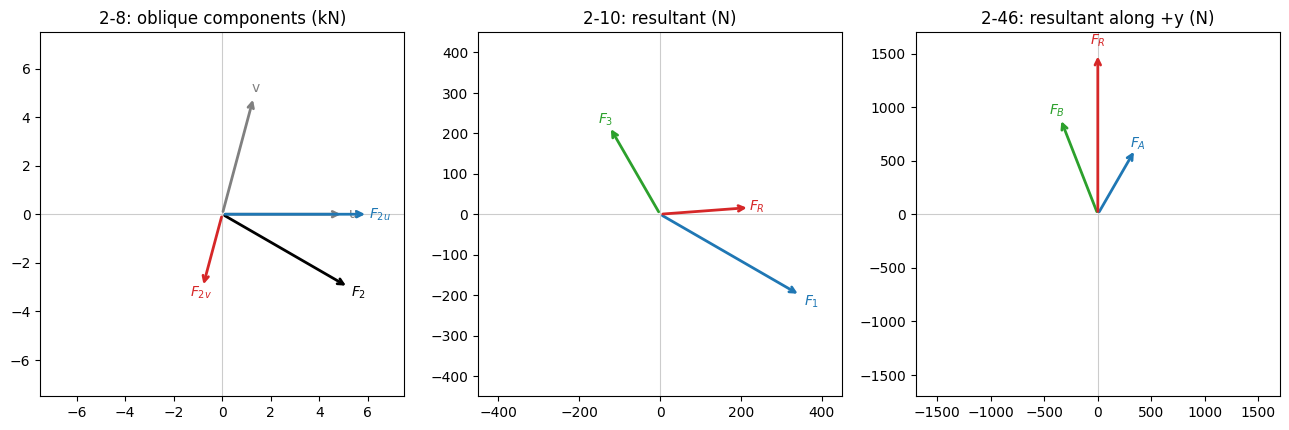

In [5]:
def arrows(ax, vecs, title, lim):
    for name, vec, color in vecs:
        x, y = float(vec[0]), float(vec[1])
        ax.annotate('', xy=(x, y), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color=color, lw=2))
        ax.text(1.08 * x, 1.08 * y, name, color=color, ha='center', va='center')
    ax.axhline(0, color='0.8', lw=0.8); ax.axvline(0, color='0.8', lw=0.8)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_aspect('equal'); ax.set_title(title)

fig, axs = plt.subplots(1, 3, figsize=(13, 4.3))
arrows(axs[0], [('u', 5 * u, '0.5'), ('v', 5 * v, '0.5'), ('$F_2$', F2, 'k'),
                ('$F_{2u}$', a * u, 'C0'), ('$F_{2v}$', b * v, 'C3')],
       '2-8: oblique components (kN)', 7.5)
arrows(axs[1], [('$F_1$', F1, 'C0'), ('$F_3$', F3, 'C2'), ('$F_R$', FR, 'C3')],
       '2-10: resultant (N)', 450)
arrows(axs[2], [('$F_A$', FA, 'C0'), ('$F_B$', FB, 'C2'), ('$F_R$', Matrix([0, 1500]), 'C3')],
       '2-46: resultant along +y (N)', 1700)
plt.tight_layout(); plt.show()

## 2-101: three cables, resultant down the pole

$B$ is at $(0,0,4)$ m. Reading the figure, cable 1 anchors at
$(-3,0,0)$ and cable 2 at $(2,-3,0)$; cable 3 anchors at the unknown
$A(x,y,0)$. Each force is its magnitude times the unit vector from $B$
to its anchor. "Directed along the pole" means the $x$ and $y$
components of the resultant are zero — two equations, two unknowns.

In [6]:
B = Matrix([0, 0, 4])
along = lambda mag, anchor: mag * (anchor - B) / (anchor - B).norm()

F1 = along(350, Matrix([-3, 0, 0]))
F2 = along(250, Matrix([2, -3, 0]))
print("F1 =", list(F1), "N")
print("F2 =", [sp.N(c, 5) for c in F2], "N")

# direction cosines of F3 that cancel the x and y components of F1 + F2
l, m = -(F1 + F2)[0] / 300, -(F1 + F2)[1] / 300
n = sqrt(1 - l**2 - m**2)                 # cosine with the downward vertical
L = 4 / n                                 # cable length BA
x_A, y_A = l * L, m * L
FR_z = (F1 + F2)[2] - 300 * n

print("\n2-101  x =", N3(x_A), "m,  y =", N3(y_A), "m")
print("2-101  FR =", N3(-FR_z), "N, from B toward O")

# independent check: solve the original equations numerically
xs, ys = sp.symbols('x y', positive=True)
F3 = along(300, Matrix([xs, ys, 0]))
tot = F1 + F2 + F3
sol = sp.nsolve([tot[0], tot[1]], [xs, ys], [2, 2])
assert abs(sol[0] - x_A) < 1e-9 and abs(sol[1] - y_A) < 1e-9
assert sig3(x_A) == 1.96 and sig3(y_A) == 2.34
assert sig3(-FR_z) == 704.0

F1 = [-210, 0, -280] N
F2 = [92.848, -139.27, -185.70] N

2-101  x = 1.96 m,  y = 2.34 m
2-101  FR = 704. N, from B toward O


# Part 3 — Electricity & magnetism: the same resultant

Coulomb's law gives each charge's field at a point as a magnitude times
a unit vector — exactly the cable forces of 2-101:

$$\mathbf E=\sum_i \frac{k\,q_i}{r_i^2}\,\hat r_i .$$

Take two equal charges $q$ at $(\pm a, 0)$ and ask for the field at
$(0,h)$. As with the cables, symmetry cancels the sideways components
and only the "along the axis" part survives.

In [7]:
k, q, a_, h = sp.symbols('k q a h', positive=True)

def E_point(charge, src, at):
    r = at - src
    return k * charge * r / r.norm()**3

P = Matrix([0, h])
E = (E_point(q, Matrix([a_, 0]), P) + E_point(q, Matrix([-a_, 0]), P)).applyfunc(sp.simplify)
print("E_x =", E[0], "  (cancels, like the x and y components in 2-101)")
print("E_y =", E[1])

# where on the axis is the field strongest?
h_max = sp.solve(sp.diff(E[1], h), h)
print("strongest at h =", h_max, " ->  E_max =", sp.simplify(E[1].subs(h, h_max[0])))
assert E[0] == 0 and sp.simplify(h_max[0] - a_ / sqrt(2)) == 0

E_x = 0   (cancels, like the x and y components in 2-101)
E_y = 2*h*k*q/(a**2 + h**2)**(3/2)
strongest at h = [sqrt(2)*a/2]  ->  E_max = 4*sqrt(3)*k*q/(9*a**2)


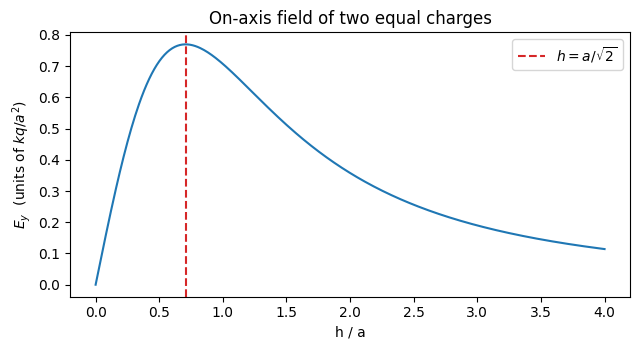

In [8]:
hh = np.linspace(0, 4, 400)
Ey = sp.lambdify(h, E[1].subs({k: 1, q: 1, a_: 1}), 'numpy')
plt.figure(figsize=(6.5, 3.6))
plt.plot(hh, Ey(hh))
plt.axvline(1 / np.sqrt(2), color='C3', ls='--', label=r'$h=a/\sqrt{2}$')
plt.xlabel('h / a'); plt.ylabel(r'$E_y$  (units of $kq/a^2$)')
plt.title('On-axis field of two equal charges'); plt.legend(); plt.tight_layout(); plt.show()

# Part 4 — Recursion

A recursion defines step $n$ in terms of step $n-1$ plus a base case.

**Resultant.** $\mathbf R_n=\mathbf R_{n-1}+\mathbf F_n$, with
$\mathbf R_0=\mathbf 0$.

**Civil load path.** In a multi-storey column the axial force below
floor $n$ is the force from above plus that floor's load:
$N_n = N_{n-1} + w$, with $N_0 = 0$ at the roof.

**Resistor ladder (E&M).** Adding one more rung to a ladder of series
$R_1$ and shunt $R_2$ gives
$R_n = R_1 + \dfrac{R_2R_{n-1}}{R_2+R_{n-1}}$.

In [9]:
def resultant(forces):
    # R_n = R_(n-1) + F_n, base case: no forces -> zero vector
    if not forces:
        return sp.zeros(3, 1)
    return resultant(forces[:-1]) + forces[-1]

F3_solved = along(300, Matrix([x_A, y_A, 0]))
R = resultant([F1, F2, F3_solved]).applyfunc(lambda c: sp.nsimplify(sp.N(c, 12), tolerance=1e-9))
print("recursive resultant for 2-101:", [sp.N(c, 4) for c in R], "N")

# column load path: closed form from the recurrence
nn = sp.symbols('n', integer=True, nonnegative=True)
w = sp.symbols('w', positive=True)
Nf = sp.Function('N')
closed = sp.rsolve(Nf(nn + 1) - Nf(nn) - w, Nf(nn), {Nf(0): 0})
print("column axial force below floor n:  N(n) =", closed)
assert sp.simplify(closed - w * nn) == 0

recursive resultant for 2-101: [0, 0, -704.2] N
column axial force below floor n:  N(n) = n*w


R_n (ohms, R1 = R2 = 1): [2, 5/3, 13/8, 34/21, 89/55, 233/144, 610/377, 1597/987]
infinite ladder: R = 1/2 + sqrt(5)/2 = 1.6180340 (the golden ratio)


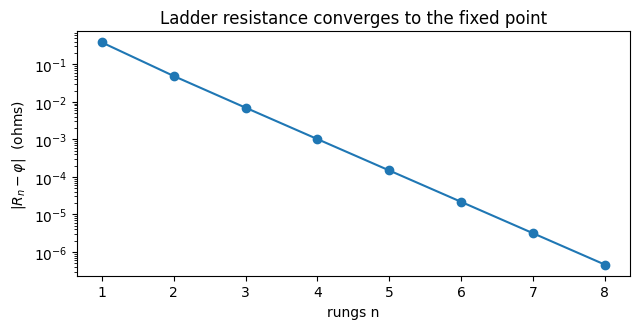

In [10]:
def ladder(n, R1=1, R2=1):
    # input resistance of an n-rung ladder
    if n == 1:
        return sp.Integer(R1 + R2)
    prev = ladder(n - 1, R1, R2)
    return R1 + sp.Rational(R2) * prev / (R2 + prev)

steps = [ladder(i) for i in range(1, 9)]
print("R_n (ohms, R1 = R2 = 1):", steps)

# the infinite ladder is the fixed point R = R1 + R2 R / (R2 + R)
Rinf = sp.symbols('R', positive=True)
fixed = sp.solve(sp.Eq(Rinf, 1 + Rinf / (1 + Rinf)), Rinf)
print("infinite ladder: R =", fixed[0], "=", sp.N(fixed[0], 8), "(the golden ratio)")
assert sp.simplify(fixed[0] - sp.GoldenRatio) == 0

plt.figure(figsize=(6.5, 3.4))
plt.semilogy(range(1, 9), [abs(float(s - fixed[0])) for s in steps], 'o-')
plt.xlabel('rungs n'); plt.ylabel(r'$|R_n - \varphi|$  (ohms)')
plt.title('Ladder resistance converges to the fixed point'); plt.tight_layout(); plt.show()

The successive values $2, \tfrac53, \tfrac{13}{8}, \tfrac{34}{21},\dots$
are ratios of Fibonacci numbers — the same recursion that defines
Fibonacci is hiding in the circuit.

# Part 5 — Photonics 101

## A polarizer resolves the field

Light's electric field is a vector transverse to the direction of
travel. An ideal polarizer keeps only the component along its
transmission axis $\hat p$ — the same projection used on forces:
$\mathbf E_{out}=(\mathbf E\cdot\hat p)\,\hat p$. Intensity goes as
$|\mathbf E|^2$, which gives **Malus's law**, $I = I_0\cos^2\theta$.

In [11]:
th, al = sp.symbols('theta alpha', real=True)

def polarizer(alpha):
    p = Matrix([cos(alpha), sin(alpha)])
    return p * p.T                       # projector onto the transmission axis

E_in  = Matrix([cos(th), sin(th)])       # unit-intensity linear polarization at angle theta
E_out = polarizer(0) * E_in
I_out = sp.simplify(E_out.dot(E_out))
print("Malus's law:  I/I0 =", I_out)
assert sp.simplify(I_out - cos(th)**2) == 0

# crossed polarizers block everything ...
x_pol = Matrix([1, 0])
crossed = polarizer(pi / 2) * x_pol
# ... unless a third polarizer at 45 degrees is slipped between them
three = polarizer(pi / 2) * polarizer(pi / 4) * x_pol
print("crossed pair:          I/I0 =", crossed.dot(crossed))
print("with 45 deg in between: I/I0 =", sp.simplify(three.dot(three)))
assert crossed.dot(crossed) == 0 and sp.simplify(three.dot(three)) == Rational(1, 4)

Malus's law:  I/I0 = cos(theta)**2
crossed pair:          I/I0 = 0
with 45 deg in between: I/I0 = 1/4


Each polarizer re-resolves the field on a new axis, so inserting one
*adds* light: the 45° component of $\hat x$ is not zero, and the 90°
component of that is not zero either.

## Why light stays in a fiber

Snell's law, $n_1\sin\theta_1=n_2\sin\theta_2$, has no solution for
$\theta_2$ once $\sin\theta_1 > n_2/n_1$: the ray is totally internally
reflected. That sets the critical angle at the core–cladding boundary
and the acceptance cone at the fiber's end face (numerical aperture
$\mathrm{NA}=\sqrt{n_1^2-n_2^2}$).

In [12]:
n1, n2 = sp.symbols('n_1 n_2', positive=True)
theta_c = sp.asin(n2 / n1)
NA = sqrt(n1**2 - n2**2)

vals = {n1: Rational(1468, 1000), n2: Rational(1463, 1000)}   # illustrative silica core / cladding
print("critical angle  =", N3(theta_c.subs(vals) / deg), "deg from the normal")
print("NA              =", N3(NA.subs(vals)))
print("acceptance half-angle in air =", N3(sp.asin(NA.subs(vals)) / deg), "deg")

# derive NA from Snell at the end face plus the critical-angle condition inside
th0 = sp.symbols('theta_0', positive=True)
inside = sp.sqrt(1 - (n2 / n1)**2)       # sin of the ray angle to the fiber axis at cutoff
assert sp.simplify(n1 * inside - NA) == 0

critical angle  = 85.3 deg from the normal
NA              = 0.121
acceptance half-angle in air = 6.95 deg


Once guided, different frequencies travel at slightly different
speeds. In the frequency domain that is a pure phase,
$H(f)=e^{\,j\pi D f^2}$ — the forward model the rest of this repository
does phase retrieval for.

# Part 6 — Digital logic: recursion in Boolean form

A full adder adds bits $a$, $b$ and a carry-in $c$:
sum $= a\oplus b\oplus c$, carry-out $=$ majority$(a,b,c)$. An $n$-bit
**ripple-carry adder** is the column recursion of Part 4 again: the
carry out of bit $k$ is the carry into bit $k+1$, just as the load
below floor $k$ is the load arriving at floor $k+1$.

In [13]:
from sympy.logic.boolalg import Xor, And, Or, simplify_logic, truth_table

A_, B_, C_ = sp.symbols('a b c')
s_bit = Xor(A_, B_, C_)
carry = Or(And(A_, B_), And(C_, Xor(A_, B_)))
print("carry-out simplifies to:", simplify_logic(carry, form='dnf'))

print("\n a b c | sum carry")
for (ai, bi, ci), sv in truth_table(s_bit, [A_, B_, C_]):
    cv = carry.subs({A_: bool(ai), B_: bool(bi), C_: bool(ci)})
    print(f" {ai} {bi} {ci} |  {int(bool(sv))}    {int(bool(cv))}")

def ripple_add(a_bits, b_bits, c_in=0):
    # bits are least-significant first; recursion on the remaining bits
    if not a_bits:
        return [c_in]
    x, y = a_bits[0], b_bits[0]
    s = x ^ y ^ c_in
    c_out = (x & y) | (c_in & (x ^ y))
    return [s] + ripple_add(a_bits[1:], b_bits[1:], c_out)

bits  = lambda v, n: [(v >> i) & 1 for i in range(n)]
value = lambda bs: sum(bit << i for i, bit in enumerate(bs))
assert all(value(ripple_add(bits(i, 4), bits(j, 4))) == i + j
           for i in range(16) for j in range(16))
print("\n4-bit ripple-carry adder matches integer addition for all 256 input pairs")

carry-out simplifies to: (a & b) | (a & c) | (b & c)

 a b c | sum carry
 0 0 0 |  0    0
 0 0 1 |  1    0
 0 1 0 |  1    0
 0 1 1 |  0    1
 1 0 0 |  1    0
 1 0 1 |  0    1
 1 1 0 |  0    1
 1 1 1 |  1    1

4-bit ripple-carry adder matches integer addition for all 256 input pairs


# Part 7 — Statistics: how sure is the answer to 2-46?

The textbook treats $F_A = 700$ N and 30° as exact. On a real bracket
they are measurements. If $F_A$ is known to ±5 N and the angle to ±0.5°
(both one standard deviation, independent), first-order error
propagation gives

$$\sigma_f^2=\sum_i\left(\frac{\partial f}{\partial x_i}\right)^2\sigma_i^2 .$$

SymPy supplies the partial derivatives; a Monte Carlo run checks the
linear approximation.

In [14]:
FA_s, phi_s = sp.symbols('F_A phi', positive=True)
Rres = 1500
FB_x = FA_s * sin(phi_s)                    # magnitude of FB's x component
FB_y = Rres - FA_s * cos(phi_s)
FB_expr = sqrt(FB_x**2 + FB_y**2)
thB_expr = sp.atan(FB_y / FB_x)

nominal = {FA_s: 700, phi_s: 30 * deg}
sig = {FA_s: 5, phi_s: Rational(1, 2) * deg}

def propagate(expr):
    var = sum((sp.diff(expr, s) * sig[s])**2 for s in sig)
    return sp.sqrt(var).subs(nominal)

s_FB, s_th = propagate(FB_expr), propagate(thB_expr) / deg
print(f"FB    = {float(FB_expr.subs(nominal)):.1f} +/- {float(s_FB):.1f} N")
print(f"theta = {float(thB_expr.subs(nominal) / deg):.2f} +/- {float(s_th):.2f} deg")

rng = np.random.default_rng(0)
n_mc = 200_000
FA_mc  = rng.normal(700, 5, n_mc)
phi_mc = rng.normal(np.radians(30), np.radians(0.5), n_mc)
FB_mc  = sp.lambdify((FA_s, phi_s), FB_expr, 'numpy')(FA_mc, phi_mc)
th_mc  = np.degrees(sp.lambdify((FA_s, phi_s), thB_expr, 'numpy')(FA_mc, phi_mc))
print(f"Monte Carlo: sigma_FB = {FB_mc.std():.2f} N, sigma_theta = {th_mc.std():.3f} deg")

assert abs(FB_mc.std() - float(s_FB)) / float(s_FB) < 0.02
assert abs(th_mc.std() - float(s_th)) / float(s_th) < 0.02

FB    = 959.9 +/- 5.7 N
theta = 68.61 +/- 0.33 deg
Monte Carlo: sigma_FB = 5.72 N, sigma_theta = 0.326 deg


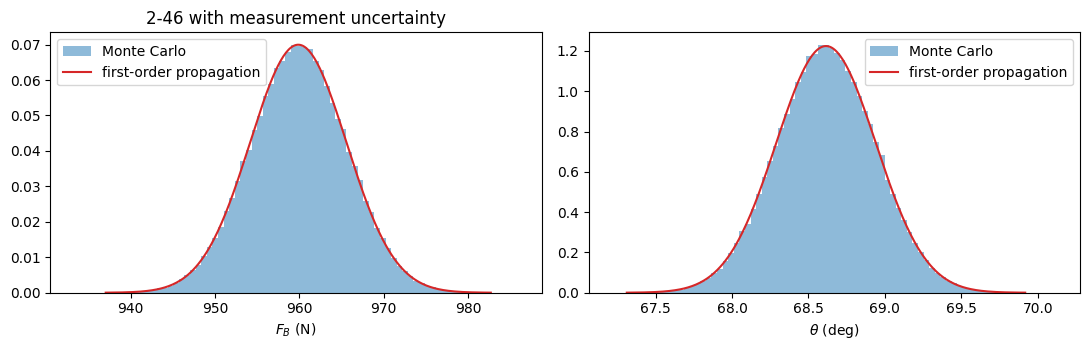

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, data, mu, s, lab in [(axs[0], FB_mc, float(FB_expr.subs(nominal)), float(s_FB), '$F_B$ (N)'),
                             (axs[1], th_mc, float(thB_expr.subs(nominal) / deg), float(s_th), r'$\theta$ (deg)')]:
    ax.hist(data, bins=80, density=True, alpha=0.5, label='Monte Carlo')
    xx = np.linspace(mu - 4 * s, mu + 4 * s, 300)
    ax.plot(xx, np.exp(-0.5 * ((xx - mu) / s)**2) / (s * np.sqrt(2 * np.pi)), 'C3',
            label='first-order propagation')
    ax.set_xlabel(lab); ax.legend()
axs[0].set_title('2-46 with measurement uncertainty'); plt.tight_layout(); plt.show()

# Part 8 — Worked steps, in the order you would write them by hand

Each line below is produced by SymPy in three stages, the way a
step-by-step solver shows its work: the **formula** in symbols, the same
formula with the **numbers substituted** but not yet evaluated, and the
**result**. `worked()` does the substitution twice — once with
display-only placeholders so nothing collapses, once with exact values.

In [16]:
from IPython.display import Math, Markdown, display

def worked(lhs, formula, values, unit='', in_deg=False):
    # values: {symbol: (exact value, text to show for it)}
    shown = formula.subs({s: sp.Symbol(d) for s, (v, d) in values.items()})
    exact = formula.subs({s: v for s, (v, d) in values.items()})
    result = sp.N(exact / deg if in_deg else exact, 4)
    tail = r'^{\circ}' if in_deg else r'\ \text{%s}' % unit
    pad = r'\phantom{%s} = ' % lhs
    display(Math(lhs + ' = ' + sp.latex(formula)))
    display(Math(pad + sp.latex(shown, mul_symbol='dot')))
    display(Math(pad + sp.latex(result) + tail))
    return exact

num = lambda v: (v, f"{float(v):.4g}")      # carry a computed value into the next step
ang = lambda d: (d * deg, r"%s^{\circ}" % d)

In [17]:
display(Markdown("### 1-12  Density of water in SI"))
rho_f, k_s, k_f = sp.symbols(r'\rho_{FPS} k_{slug} k_{ft}')
worked(r'\rho', rho_f * k_s / k_f**3,
       {rho_f: (Rational(194, 100), '1.94'), k_s: (Rational(1459, 100), '14.59'), k_f: (ft, '0.3048')},
       'kg/m³')
display(Markdown("Round to three significant figures: **1.00 Mg/m³**."))

display(Markdown("### 1-18  Evaluate (204 mm)(0.00457 kg)/(34.6 N)"))
w_L, w_m, w_F = sp.symbols('L m F')
worked('Q', w_L * w_m / w_F,
       {w_L: (Rational(204, 1000), '0.204'), w_m: (Rational(457, 100000), '0.00457'),
        w_F: (Rational(346, 10), '34.6')}, 'm·kg/N')
display(Markdown("Move the factor 10⁻⁶ into the prefix: **26.9 μm·kg/N**."))

display(Markdown("### 1-19  Density of brass from specific weight"))
w_gam, k_lb, w_g = sp.symbols(r'\gamma k_{lb} g')
worked(r'\rho', w_gam * k_lb / (k_f**3 * w_g),
       {w_gam: (520, '520'), k_lb: (Rational(4448, 1000), '4.448'), k_f: (ft, '0.3048'),
        w_g: (g, '9.81')}, 'kg/m³')
display(Markdown("**8.33 Mg/m³**."))

### 1-12  Density of water in SI

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Round to three significant figures: **1.00 Mg/m³**.

...

### 1-19  Density of brass from specific weight

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**8.33 Mg/m³**.

In [18]:
display(Markdown('''### 2-8  Components of F₂ along u and v
Triangle of forces: the angle between **F₂** and *u* is 30°, between **F₂** and −*v* is
180° − 75° − 30° = 75°, so the third angle is 180° − 30° − 75° = 75°.
Two equal angles make the triangle isosceles, so the side opposite the second 75° angle
equals F₂: **F₂ᵤ = 6.00 kN**. The law of sines gives the other side:'''))
w_F2, w_al, w_ga = sp.symbols(r'F_2 alpha gamma')
worked('F_{2v}', w_F2 * sin(w_al) / sin(w_ga), {w_F2: (6, '6'), w_al: ang(30), w_ga: ang(75)}, 'kN')
display(Markdown("Directed along −*v*: **F₂ᵥ = 3.11 kN** (or −3.11 kN as a signed component)."))

display(Markdown("### 2-10  Resultant of F₁ and F₃"))
w_F1, w_F3, w_t1, w_t3, w_Rx, w_Ry = sp.symbols(r'F_1 F_3 theta_1 theta_3 F_{Rx} F_{Ry}')
given = {w_F1: (400, '400'), w_F3: (250, '250'), w_t1: ang(30), w_t3: ang(30)}
Rx = worked('F_{Rx}', w_F1 * cos(w_t1) - w_F3 * sin(w_t3), given, 'N')
Ry = worked('F_{Ry}', -w_F1 * sin(w_t1) + w_F3 * cos(w_t3), given, 'N')
comps = {w_Rx: num(Rx), w_Ry: num(Ry)}
worked('F_R', sqrt(w_Rx**2 + w_Ry**2), comps, 'N')
worked(r'\theta', sp.atan(w_Ry / w_Rx), comps, in_deg=True)
display(Markdown("**F_R = 222 N at θ = 4.26°** counterclockwise from +x."))

display(Markdown('''### 2-46  F_B for a 1500 N resultant along +y
ΣFₓ = 0 gives F_B cos θ; ΣF_y = 1500 gives F_B sin θ.'''))
w_FA, w_ph, w_R, w_Bx, w_By = sp.symbols(r'F_A phi F_R F_{Bx} F_{By}')
given = {w_FA: (700, '700'), w_ph: ang(30), w_R: (1500, '1500')}
Bx = worked(r'F_B\cos\theta', w_FA * sin(w_ph), given, 'N')
By = worked(r'F_B\sin\theta', w_R - w_FA * cos(w_ph), given, 'N')
comps = {w_Bx: num(Bx), w_By: num(By)}
worked(r'\theta', sp.atan(w_By / w_Bx), comps, in_deg=True)
worked('F_B', sqrt(w_Bx**2 + w_By**2), comps, 'N')
display(Markdown("**F_B = 960 N, θ = 68.6°.**"))

### 2-8  Components of F₂ along u and v
Triangle of forces: the angle between **F₂** and *u* is 30°, between **F₂** and −*v* is
180° − 75° − 30° = 75°, so the third angle is 180° − 30° − 75° = 75°.
Two equal angles make the triangle isosceles, so the side opposite the second 75° angle
equals F₂: **F₂ᵤ = 6.00 kN**. The law of sines gives the other side:

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Directed along −*v*: **F₂ᵥ = 3.11 kN** (or −3.11 kN as a signed component).

...

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**F_B = 960 N, θ = 68.6°.**

In [19]:
display(Markdown('''### 2-101  Anchor position A and the resultant
Unit vectors from B(0, 0, 4): cable 1 to (−3, 0, 0) has length 5; cable 2 to (2, −3, 0) has
length √29. So **F₁** = 350(−3**i** − 4**k**)/5 = {−210**i** − 280**k**} N and
**F₂** = 250(2**i** − 3**j** − 4**k**)/√29 = {92.85**i** − 139.27**j** − 185.70**k**} N.
Write **F₃** = 300(ℓ**i** + m**j** − n**k**) with ℓ = x/L, m = y/L, n = 4/L.'''))
w_a, w_b, w_c, w_F3m, w_l, w_m_, w_n, w_h, w_Lc = sp.symbols(r'F_{1x} F_{2x} F_{2y} F_3 ell m n h L')
F2x, F2y, F2z = 250 * 2 / sqrt(29), 250 * 3 / sqrt(29), 250 * 4 / sqrt(29)   # magnitudes
display(Markdown("ΣFₓ = 0 and ΣF_y = 0:"))
l_w = worked(r'\ell', (w_a - w_b) / w_F3m, {w_a: (210, '210'), w_b: num(F2x), w_F3m: (300, '300')})
m_w = worked('m', w_c / w_F3m, {w_c: num(F2y), w_F3m: (300, '300')})
display(Markdown("Direction cosines satisfy ℓ² + m² + n² = 1:"))
n_w = worked('n', sqrt(1 - w_l**2 - w_m_**2), {w_l: num(l_w), w_m_: num(m_w)})
L_w = worked('L', w_h / w_n, {w_h: (4, '4'), w_n: num(n_w)}, 'm')
worked('x', w_l * w_Lc, {w_l: num(l_w), w_Lc: num(L_w)}, 'm')
worked('y', w_m_ * w_Lc, {w_m_: num(m_w), w_Lc: num(L_w)}, 'm')
display(Markdown("All three z components point down the pole:"))
w_1z, w_2z = sp.symbols('F_{1z} F_{2z}')
FR_w = worked('F_R', w_1z + w_2z + w_F3m * w_n,
              {w_1z: (280, '280'), w_2z: num(F2z), w_F3m: (300, '300'), w_n: num(n_w)}, 'N')
display(Markdown("**x = 1.96 m, y = 2.34 m, F_R = 704 N** from B toward O."))
assert abs(sp.N(FR_w + FR_z)) < 1e-9 and abs(sp.N(l_w * L_w - x_A)) < 1e-9

### 2-101  Anchor position A and the resultant
Unit vectors from B(0, 0, 4): cable 1 to (−3, 0, 0) has length 5; cable 2 to (2, −3, 0) has
length √29. So **F₁** = 350(−3**i** − 4**k**)/5 = {−210**i** − 280**k**} N and
**F₂** = 250(2**i** − 3**j** − 4**k**)/√29 = {92.85**i** − 139.27**j** − 185.70**k**} N.
Write **F₃** = 300(ℓ**i** + m**j** − n**k**) with ℓ = x/L, m = y/L, n = 4/L.

ΣFₓ = 0 and ΣF_y = 0:

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

...

All three z components point down the pole:

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**x = 1.96 m, y = 2.34 m, F_R = 704 N** from B toward O.

# Part 9 — Forces as exponentials (Feynman, Vol. I, Ch. 22)

Feynman's "Algebra" chapter builds up to
$e^{i\theta}=\cos\theta+i\sin\theta$. A planar force of magnitude $F$
at angle $\theta$ is then one complex number, $F e^{i\theta}$: the real
part is the $x$ component, the imaginary part the $y$ component. Adding
forces is adding exponentials, and the resultant's magnitude and angle
are the modulus and argument of the sum.

In [20]:
I = sp.I
phasor = lambda mag, d: mag * sp.exp(I * d * deg)

# 2-10 again, as two exponentials
zR = sp.expand_complex(phasor(400, -30) + phasor(250, 120))
print("2-10  F_R =", zR)
print("      |F_R| =", sp.N(sp.Abs(zR), 4), "N,  arg =", sp.N(sp.arg(zR) / deg, 4), "deg")
assert abs(sp.N(sp.Abs(zR) - FR_mag)) < 1e-12

# 2-46: FB = (1500 N along +y) - FA
zB = sp.expand_complex(1500 * I - phasor(700, 60))
print("2-46  F_B =", zB)
print("      |F_B| =", sp.N(sp.Abs(zB), 4), "N,  angle above -x =", sp.N(180 - sp.arg(zB) / deg, 4), "deg")
assert abs(sp.N(sp.Abs(zB) - FB_mag)) < 1e-12

# equilibrium: N equal forces spaced evenly around a pin sum to zero (roots of unity)
for N_f in (3, 5, 8):
    total = sum(sp.exp(2 * pi * I * j / N_f) for j in range(N_f))
    assert abs(sp.N(total)) < 1e-12
print("\nN equal, evenly spaced forces: resultant = 0 for N = 3, 5, 8")

2-10  F_R = -125 + 200*sqrt(3) + I*(-200 + 125*sqrt(3))
      |F_R| = 222.0 N,  arg = 4.264 deg
2-46  F_B = -350 + I*(1500 - 350*sqrt(3))
      |F_B| = 959.9 N,  angle above -x = 68.62 deg

N equal, evenly spaced forces: resultant = 0 for N = 3, 5, 8


## Many exponentials at once

Add $N$ equal phasors, each rotated by the same angle $\varphi$ from the
last. It is a geometric series:

$$\sum_{j=0}^{N-1}e^{ij\varphi}=\frac{1-e^{iN\varphi}}{1-e^{i\varphi}},\qquad
\left|\sum\right|=\left|\frac{\sin(N\varphi/2)}{\sin(\varphi/2)}\right| .$$

In statics this is the closing polygon of $N$ equal forces. In optics
(Feynman Vol. I, Ch. 29–30) it is the light from $N$ slits, and the
squared magnitude is the diffraction-grating pattern.

geometric-series magnitude verified for N = 2 and N = 6


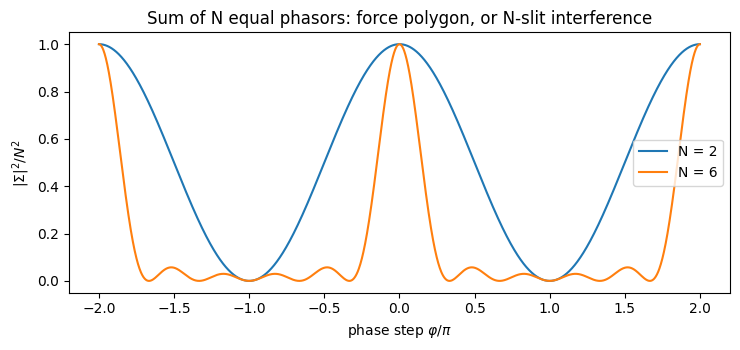

In [21]:
phi = sp.symbols('varphi', real=True)

def phasor_sum(N_s):
    return sum(sp.exp(I * j * phi) for j in range(N_s))

closed_form = lambda N_s: sin(N_s * phi / 2) / sin(phi / 2)
for N_s in (2, 6):
    for test in (0.3, 1.1, 2.7):
        lhs_v = abs(complex(phasor_sum(N_s).subs(phi, test)))
        rhs_v = abs(float(closed_form(N_s).subs(phi, test)))
        assert abs(lhs_v - rhs_v) < 1e-12
print("geometric-series magnitude verified for N = 2 and N = 6")

pp = np.linspace(-2 * np.pi, 2 * np.pi, 2001) + 1e-9
plt.figure(figsize=(7.5, 3.6))
for N_s in (2, 6):
    inten = np.abs(sp.lambdify(phi, phasor_sum(N_s), 'numpy')(pp))**2 / N_s**2
    plt.plot(pp / np.pi, inten, label=f'N = {N_s}')
plt.xlabel(r'phase step $\varphi/\pi$'); plt.ylabel(r'$|\Sigma|^2/N^2$')
plt.title('Sum of N equal phasors: force polygon, or N-slit interference')
plt.legend(); plt.tight_layout(); plt.show()

# Part 10 — The same answers from C and MATLAB

[`scripts/statics_hw2.c`](../scripts/statics_hw2.c) and
[`scripts/statics_hw2.m`](../scripts/statics_hw2.m) redo all seven
problems in floating point and print one `key value` pair per line. The
cell below compiles and runs the C version with gcc when it is
available and compares every value with the SymPy result. The MATLAB
script prints the same keys; run it with
`matlab -batch "run('scripts/statics_hw2.m')"`.

In [22]:
import os, pathlib, shutil, subprocess, tempfile

expected = {
    '1-12_rho_Mg_m3': rho_water / 1000, '1-18_um_kg_N': val * 10**6, '1-19_rho_Mg_m3': rho_brass / 1000,
    '2-8_F2u_kN': a, '2-8_F2v_kN': -b,
    '2-10_FR_N': FR_mag, '2-10_theta_deg': theta / deg,
    '2-46_FB_N': FB_mag, '2-46_theta_deg': theta_B / deg,
    '2-101_x_m': x_A, '2-101_y_m': y_A, '2-101_FR_N': -FR_z,
}

src = next((p for p in (pathlib.Path('scripts/statics_hw2.c'), pathlib.Path('../scripts/statics_hw2.c'))
            if p.exists()), None)
gcc = shutil.which('gcc') or (r'C:\msys64\mingw64\bin\gcc.exe'
                              if os.path.exists(r'C:\msys64\mingw64\bin\gcc.exe') else None)

if src is None or gcc is None:
    print("gcc or the C source was not found; skipping the C cross-check")
else:
    env = dict(os.environ, PATH=os.path.dirname(gcc) + os.pathsep + os.environ['PATH'])
    with tempfile.TemporaryDirectory() as tmp:
        exe = os.path.join(tmp, 'statics_hw2.exe')
        subprocess.run([gcc, '-O2', '-Wall', '-o', exe, str(src), '-lm'], check=True, env=env)
        out = subprocess.run([exe], check=True, capture_output=True, text=True, env=env).stdout
    print(f"{'quantity':<18}{'C (gcc)':>14}{'SymPy':>14}")
    for line in out.strip().splitlines():
        key, c_val = line.split()
        s_val = float(expected[key])
        print(f"{key:<18}{float(c_val):>14.6f}{s_val:>14.6f}")
        assert abs(float(c_val) - s_val) < 1e-5, key
    print("\nC and SymPy agree on all", len(expected), "values")

quantity                 C (gcc)         SymPy
1-12_rho_Mg_m3          0.999835      0.999835
1-18_um_kg_N           26.944509     26.944509
1-19_rho_Mg_m3          8.326756      8.326756
2-8_F2u_kN              6.000000      6.000000
2-8_F2v_kN              3.105829      3.105829
2-10_FR_N             222.024592    222.024592
2-10_theta_deg          4.263571      4.263571
2-46_FB_N             959.868039    959.868039
2-46_theta_deg         68.614973     68.614973
2-101_x_m               1.964879      1.964879
2-101_y_m               2.335862      2.335862
2-101_FR_N            704.188063    704.188063

C and SymPy agree on all 12 values


# Part 11 — Reading map and time budget

**Reading that this homework draws on**

| Source | Chapter | Why |
|---|---|---|
| Hibbeler, *Statics* | 1, General Principles | units, prefixes, significant figures (1-12, 1-18, 1-19) |
| Hibbeler, *Statics* | 2, Force Vectors | parallelogram law, Cartesian vectors, position vectors (2-8 to 2-101) |
| Feynman Lectures, Vol. I | 11, Vectors | what a vector is and why components add |
| Feynman Lectures, Vol. I | 12, Characteristics of Force | what the arrows in a free-body diagram mean |
| Feynman Lectures, Vol. I | 22, Algebra | $e^{i\theta}$, used in Part 9 |
| Feynman Lectures, Vol. I | 29–30, Interference and Diffraction | the sum of many exponentials, Part 9 |
| Feynman Lectures, Vol. II | 4, Electrostatics | superposition of fields, Part 3 |

**Time budget for writing the seven problems out by hand**

| Problems | Each | Subtotal |
|---|---|---|
| 1-12, 1-18, 1-19 (unit conversions) | about 10 min | 30 min |
| 2-8, 2-10, 2-46 (planar, with a sketch) | about 20 min | 60 min |
| 2-101 (three dimensions) | about 35 min | 35 min |
| Checking against Part 8 | | 15 min |
| **Total** | | **about 2 to 2.5 hours** |

# Part 12 — Smart contracts on Ethereum

A **smart contract** is a small program stored on the Ethereum
blockchain together with its own state and its own balance. Anyone can
send it a transaction that calls one of its functions; every node in the
network re-runs that call and must arrive at the same new state. Three
consequences shape how contracts are written:

- **Integers only.** Nodes must agree bit for bit, so there is no
  floating point. Money is counted in **wei**, with
  $1\ \text{ETH}=10^{18}$ wei and $1\ \text{gwei}=10^{9}$ wei — the same
  "keep it exact until the last step" rule as the rational conversion
  factors of Part 1.
- **All or nothing.** A call either finishes or *reverts*, undoing
  every change it made.
- **Computation is metered.** Each operation costs **gas**; the sender
  pays gas used × gas price. A plain ETH transfer costs 21 000 gas.

This part is a **Python model** of those rules — nothing here touches a
real network or real money.

In [23]:
WEI_PER_ETH  = 10**18
WEI_PER_GWEI = 10**9
to_wei = lambda eth: int(Rational(str(eth)) * WEI_PER_ETH)

# why integers: binary floats cannot represent 0.1 exactly
print("0.1 + 0.2 == 0.3 with floats?      ", 0.1 + 0.2 == 0.3)
print("same sum counted in wei (integers)?", to_wei('0.1') + to_wei('0.2') == to_wei('0.3'))

# fee for a plain ETH transfer = gas used x gas price
gas_transfer = 21_000
gas_price = 20 * WEI_PER_GWEI          # illustrative; the real price moves with demand
fee = gas_transfer * gas_price
print(f"\ntransfer fee at 20 gwei: {fee} wei = {Rational(fee, WEI_PER_ETH)} ETH"
      f" = {float(Rational(fee, WEI_PER_ETH))} ETH")
assert to_wei('0.1') + to_wei('0.2') == to_wei('0.3')
assert fee == 420_000 * WEI_PER_GWEI

0.1 + 0.2 == 0.3 with floats?       False
same sum counted in wei (integers)? True

transfer fee at 20 gwei: 420000000000000 wei = 21/50000 ETH = 0.00042 ETH


## An escrow that pays on a passing inspection

Tie it back to problem 2-46. A client hires a contractor to tension
cable $B$ to the design force $F_B = 960$ N. The client locks the
payment in a contract; an inspector reports the measured force; the
contract releases the money to the contractor if the measurement is
within tolerance of the design value, and refunds the client if not.
The tolerance is taken as $3\sigma$ from Part 7. Forces go on-chain as
whole **millinewtons**, because there are no decimals.

The contract is a **state machine**, like the sequential logic that
follows Part 6's combinational adder:

`AwaitingDeposit → Funded → Released` or `Refunded`

In Solidity, Ethereum's main contract language, it would read as below.
This listing is for reading only — it is **not compiled or deployed**
by this notebook.

```solidity
// SPDX-License-Identifier: MIT
pragma solidity ^0.8.20;

contract CableEscrow {
    enum State { AwaitingDeposit, Funded, Released, Refunded }

    address payable public immutable client;
    address payable public immutable contractor;
    address public immutable inspector;
    uint256 public immutable price;        // wei
    uint256 public immutable designForce;  // millinewtons
    uint256 public immutable tolerance;    // millinewtons
    State public state;

    constructor(address payable _contractor, address _inspector,
                uint256 _price, uint256 _designForce, uint256 _tolerance) {
        client = payable(msg.sender);
        contractor = _contractor;
        inspector = _inspector;
        price = _price;
        designForce = _designForce;
        tolerance = _tolerance;
    }

    function deposit() external payable {
        require(msg.sender == client, "only client");
        require(state == State.AwaitingDeposit, "wrong state");
        require(msg.value == price, "wrong amount");
        state = State.Funded;
    }

    function attest(uint256 measuredForce) external {
        require(msg.sender == inspector, "only inspector");
        require(state == State.Funded, "wrong state");
        uint256 diff = measuredForce > designForce
            ? measuredForce - designForce
            : designForce - measuredForce;
        bool passed = diff <= tolerance;
        address payable payee = passed ? contractor : client;
        state = passed ? State.Released : State.Refunded;   // update state first
        (bool ok, ) = payee.call{value: price}("");         // then send the money
        require(ok, "payment failed");
    }
}
```

The Python model below mirrors it function for function.

In [24]:
class Revert(Exception):
    pass

def require(condition, message):
    if not condition:
        raise Revert(message)

class Ledger:
    # account balances in wei; value only ever moves, it is never created
    def __init__(self, balances):
        self.bal = dict(balances)
    def move(self, src, dst, amount):
        require(self.bal[src] >= amount, "insufficient balance")
        self.bal[src] -= amount
        self.bal[dst] += amount
    def total(self):
        return sum(self.bal.values())

class CableEscrow:
    def __init__(self, ledger, client, contractor, inspector, price, design_mN, tol_mN):
        self.ledger, self.client, self.contractor, self.inspector = ledger, client, contractor, inspector
        self.price, self.design_mN, self.tol_mN = price, design_mN, tol_mN
        self.state = 'AwaitingDeposit'

    def deposit(self, sender, value):
        require(sender == self.client, "only client")
        require(self.state == 'AwaitingDeposit', "wrong state")
        require(value == self.price, "wrong amount")
        self.ledger.move(sender, 'escrow', value)
        self.state = 'Funded'

    def attest(self, sender, measured_mN):
        require(sender == self.inspector, "only inspector")
        require(self.state == 'Funded', "wrong state")
        passed = abs(measured_mN - self.design_mN) <= self.tol_mN
        self.state = 'Released' if passed else 'Refunded'              # update state first
        self.ledger.move('escrow', self.contractor if passed else self.client, self.price)

design_mN = round(float(FB_expr.subs(nominal)) * 1000)     # 2-46 answer, in millinewtons
tol_mN    = round(3 * float(s_FB) * 1000)                  # 3 sigma from Part 7
price     = to_wei(2)
print(f"design force = {design_mN} mN, tolerance = +/- {tol_mN} mN, price = {price} wei")

def new_job():
    ledger = Ledger({'client': to_wei(5), 'contractor': 0, 'inspector': 0, 'escrow': 0})
    return ledger, CableEscrow(ledger, 'client', 'contractor', 'inspector', price, design_mN, tol_mN)

eth = lambda wei: float(Rational(wei, WEI_PER_ETH))
for measured_N in (962, 990):
    ledger, job = new_job()
    job.deposit('client', price)
    job.attest('inspector', measured_N * 1000)
    print(f"measured {measured_N} N -> {job.state:9s}"
          f" client {eth(ledger.bal['client'])} ETH, contractor {eth(ledger.bal['contractor'])} ETH")
    assert ledger.total() == to_wei(5)                     # value is conserved
    assert job.state == ('Released' if measured_N == 962 else 'Refunded')

design force = 959868 mN, tolerance = +/- 17108 mN, price = 2000000000000000000 wei
measured 962 N -> Released  client 3.0 ETH, contractor 2.0 ETH
measured 990 N -> Refunded  client 5.0 ETH, contractor 0.0 ETH


Two things to notice. The total number of wei never changes —
a conservation law the ledger obeys the way a free body obeys
$\sum\mathbf F=\mathbf 0$. And the rules are enforced by `require`:
a call from the wrong account, or in the wrong state, reverts and
leaves everything as it was.

In [25]:
ledger, job = new_job()
job.deposit('client', price)
before = (job.state, dict(ledger.bal))

attempts = [("contractor approves own work", lambda: job.attest('contractor', 960_000)),
            ("client deposits a second time", lambda: job.deposit('client', price)),
            ("inspector attests twice", lambda: (job.attest('inspector', 960_000),
                                                 job.attest('inspector', 960_000)))]
for label, call in attempts[:2]:
    try:
        call()
        raise AssertionError("should have reverted")
    except Revert as why:
        print(f"{label:30s} -> reverted: {why}")
    assert (job.state, ledger.bal) == before               # nothing changed

label, call = attempts[2]
try:
    call()
    raise AssertionError("should have reverted")
except Revert as why:
    print(f"{label:30s} -> second call reverted: {why}")
assert ledger.bal['contractor'] == price                   # paid once, not twice

contractor approves own work   -> reverted: only inspector
client deposits a second time  -> reverted: wrong state
inspector attests twice        -> second call reverted: wrong state


## Why history cannot be quietly edited: a recursion again

Each block stores the hash of the block before it,
$h_n = H(h_{n-1}\,\Vert\,\text{data}_n)$ — the same "step $n$ from step
$n-1$" structure as the column load path and the ripple carry. Change
one old record and every later hash changes with it.

(Ethereum uses Keccak-256. Python's standard library offers the closely
related NIST SHA3-256, which pads its input differently and so gives
different digests; it is used here only to show the chaining.)

In [26]:
import hashlib, json

def block_hash(prev_hash, payload):
    text = prev_hash + json.dumps(payload, sort_keys=True)
    return hashlib.sha3_256(text.encode()).hexdigest()

def chain_hashes(payloads, genesis='00' * 32):
    # h_n = H(h_(n-1) || payload_n), base case: the genesis hash
    if not payloads:
        return [genesis]
    earlier = chain_hashes(payloads[:-1], genesis)
    return earlier + [block_hash(earlier[-1], payloads[-1])]

log = [{'call': 'deposit', 'from': 'client',    'value': price},
       {'call': 'attest',  'from': 'inspector', 'measured_mN': 990_000},
       {'call': 'refund',  'to': 'client',      'value': price},
       {'call': 'note',    'text': 'job closed'}]
forged = [dict(entry) for entry in log]
forged[1]['measured_mN'] = 962_000          # rewrite the failed inspection as a pass

honest, tampered = chain_hashes(log), chain_hashes(forged)
print("block   honest      forged")
for i, (h, t) in enumerate(zip(honest, tampered)):
    print(f"  {i}     {h[:8]}    {t[:8]}   {'same' if h == t else 'DIFFERENT'}")
assert honest[:2] == tampered[:2] and all(h != t for h, t in zip(honest[2:], tampered[2:]))

block   honest      forged
  0     00000000    00000000   same
  1     f26f91d6    f26f91d6   same
  2     569f198e    36819cec   DIFFERENT
  3     4fd68a10    97386874   DIFFERENT
  4     9849b897    70d5f5f2   DIFFERENT


## What this model leaves out

- **Consensus.** Real blocks are agreed on by thousands of validators;
  here there is one Python process.
- **Signatures.** "Only the inspector may call `attest`" is enforced on
  Ethereum by an elliptic-curve signature on every transaction; here it
  is a string comparison. See
  [`shor_discrete_log_ethereum.ipynb`](shor_discrete_log_ethereum.ipynb)
  for the mathematics that signature rests on.
- **Real gas metering.** Only the 21 000-gas transfer fee is computed;
  contract calls cost more, depending on the operations they run.
- **The oracle problem.** A blockchain cannot measure a cable. The
  contract enforces the rule perfectly but trusts whatever number the
  inspector's key submits — the engineering judgment stays off-chain.

# Summary

| Problem | Answer (three significant figures) |
|---|---|
| 1-12 | $\rho = 1.00\ \text{Mg/m}^3$ |
| 1-18 | $26.9\ \mu\text{m·kg/N}$ |
| 1-19 | $\rho = 8.33\ \text{Mg/m}^3$ |
| 2-8 | $F_{2u} = 6.00$ kN, $F_{2v} = 3.11$ kN along $-v$ |
| 2-10 | $F_R = 222$ N, $\theta = 4.26°$ |
| 2-46 | $F_B = 960$ N, $\theta = 68.6°$ |
| 2-101 | $x = 1.96$ m, $y = 2.34$ m, $F_R = 704$ N |

Every answer above is asserted in the cell that computes it, so the
notebook fails to execute if any of them drifts.

| Idea from the homework | Where it came back |
|---|---|
| Resolve a vector on axes (inner product, Gram matrix) | Polarizer projection and Malus's law |
| Add vectors, cancel components | On-axis field of two charges |
| Step $n$ from step $n-1$ | Column load path, resistor ladder, ripple carry |
| An exact answer from exact inputs | Its uncertainty when the inputs are measured |
| Exact units, no rounding until the end | Wei and millinewtons in the escrow contract |
| Something is conserved ($\sum\mathbf F=\mathbf 0$) | Total wei on the ledger |